In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Task 1 — Load & Inspect the Data (Red + White)

Instructions

Train Model A on both datasets using a Pipeline:
*   StandardScaler()
*   LogisticRegression(max_iter=5000)

Evaluate on test set (must include)
* Accuracy
* Confusion Matrix
* Classification Report
* F1-score (use macro F1-score consistently and mention that)

Deliverables
* Results for red + results for white
* 4–6 lines answering:
* Which dataset performed better for Logistic Regression?
* Which quality class looks hardest (lowest recall)?

In [6]:
dfWineRed = pd.read_csv("winequality-red.csv", sep=';')
dfWineWhite = pd.read_csv("winequality-white.csv", sep=';')
#dfWineRed.head()
dfWineWhite.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [7]:
dfWineRed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [8]:
dfWineWhite.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [9]:
dfWineRed.shape

(1599, 12)

In [10]:
dfWineWhite.shape

(4898, 12)

In [11]:
dfWineWhite.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [12]:
dfWineRed.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [13]:
if 'quality' in dfWineRed.columns: print("Column exists!")

Column exists!


In [14]:
if 'quality' in dfWineWhite.columns: print("Column exists!")

Column exists!


## Task 2 — Data Quality Checks + Class Distribution (Comparative)

Instructions (do for red and white separately)
1. Check missing values per column.
2. Check duplicates.
3. Show quality class distribution:
○ counts
○ percentages
4. Plot a bar chart of quality counts.

Deliverables

In [15]:
dfWineRed.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [16]:
dfWineWhite.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


/tmp/ipykernel_2060/306178502.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(dfWineRed['quality']).plot.bar()


<Axes: xlabel='quality'>

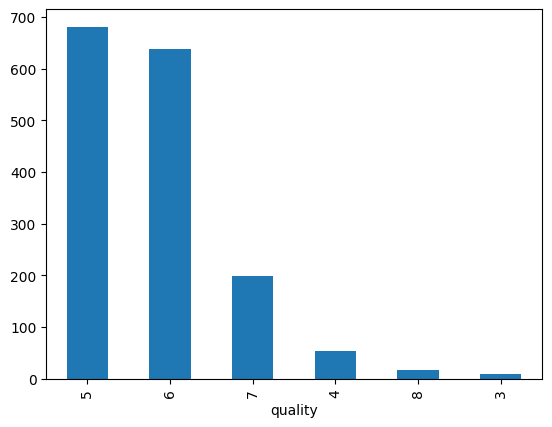

In [17]:
# 2 bar charts (red + white)
pd.value_counts(dfWineRed['quality']).plot.bar()

/tmp/ipykernel_2060/2866218827.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(dfWineWhite['quality']).plot.bar()


<Axes: xlabel='quality'>

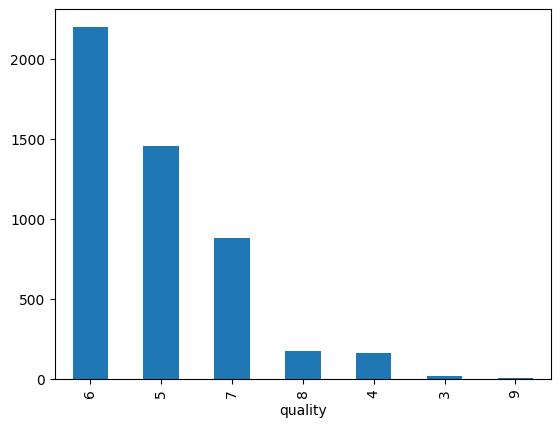

In [18]:
pd.value_counts(dfWineWhite['quality']).plot.bar()

In [19]:
#describe dataset
dfWineRed.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [20]:
dfWineWhite.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [21]:
num_cols_WineWhite = dfWineWhite.select_dtypes(include=np.number).columns.tolist()
num_cols_WineRed = dfWineRed.select_dtypes(include=np.number).columns.tolist()
num_cols_WineRed

['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol',
 'quality']

In [22]:
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask


In [23]:
#columns number
num_col_i=6

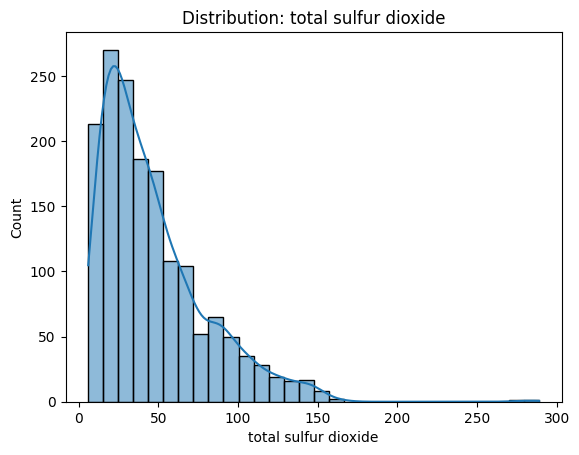

IQR bounds: -38.0 122.0
Outliers: 55 (3.44%)
skew: 1.515531257594554
kurtosis: 3.8098244878645744


In [24]:
#WineRed data
num_cols = num_cols_WineRed
df=dfWineRed
example_num = num_cols[num_col_i] if num_cols else None
if example_num:
    sns.histplot(df[example_num], bins=30, kde=True)
    plt.title(f"Distribution: {example_num}")
    plt.show()
else:
    print("No numeric columns to plot.")

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)


if example_num:
    print("skew:", df[example_num].skew())
    print("kurtosis:", df[example_num].kurt())

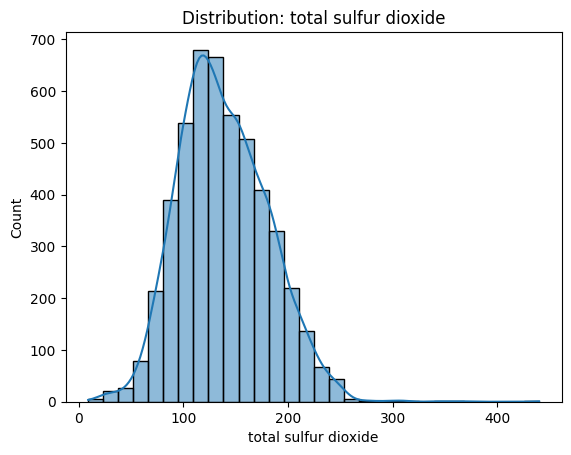

IQR bounds: 19.5 255.5
Outliers: 19 (0.39%)
skew: 0.3907098416536745
kurtosis: 0.5718532333534614


In [25]:
#WineWhite data
num_cols = num_cols_WineWhite
df=dfWineWhite
example_num = num_cols[num_col_i] if num_cols else None
if example_num:
    sns.histplot(df[example_num], bins=30, kde=True)
    plt.title(f"Distribution: {example_num}")
    plt.show()
else:
    print("No numeric columns to plot.")

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

if example_num:
    print("skew:", df[example_num].skew())
    print("kurtosis:", df[example_num].kurt())

Comparative Questions (answer in 4–6 lines)

● Which dataset is more imbalanced?

The Red Wine dataset is more imbalanced than White Wine dataset especially for "Total Sulfur dioxide". The Total Sulfur dioxide content is more imbalanced than other columns. The imbalance is more evident in skew: 1.51 and kurtosis: 3.80. Also, the mean is 46 while 75% quartile 62 but the Max 289 which has 55 outliers which is 3.44%.


● Which quality classes are rare?

9 is the rarest quality classes.

● Why might rare classes be harder to predict?

There is not enough data having quality 9 in Red and white wine.

## Task 3 — Prepare Data for Modeling (Same Setup for Fair Comparison)

Instructions (do for both datasets)
1. Create:
○ X = all columns except quality
○ y = quality
2. Train-test split with:
○ test_size=0.2
○ random_state=42
○ stratify=y

Deliverables
● Train/test shapes for red and white
● 1–2 lines confirming stratification preserved similar class distribution

In [31]:
from sklearn.model_selection import train_test_split

# training and test date split for Red Wine
X_red = dfWineRed.drop(columns=['quality'])
y_red = dfWineRed['quality']

X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(
    X_red, y_red, test_size=0.2, random_state=42, stratify=y_red
)

# training and test date split for White Wine
X_white = dfWineWhite.drop(columns=['quality'])
y_white = dfWineWhite['quality']

X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(
    X_white, y_white, test_size=0.2, random_state=42, stratify=y_white
)

#Rows column shapes of red and white wine results
print("Red Wine Train/Test")
print(f"X_train: {X_red_train.shape}, y_train: {y_red_train.shape}")
print(f"X_test:  {X_red_test.shape}, y_test:  {y_red_test.shape}\n")

print("White Wine Train/Test")
print(f"X_train: {X_white_train.shape}, y_train: {y_white_train.shape}")
print(f"X_test:  {X_white_test.shape}, y_test:  {y_white_test.shape}\n")

Red Wine Train/Test
X_train: (1279, 11), y_train: (1279,)
X_test:  (320, 11), y_test:  (320,)

White Wine Train/Test
X_train: (3918, 11), y_train: (3918,)
X_test:  (980, 11), y_test:  (980,)



## Task 4 — Model A (Baseline): Logistic Regression (Red vs White)

Instructions

Train Model A on both datasets using a Pipeline:
*   StandardScaler()
*   LogisticRegression(max_iter=5000)

Evaluate on test set (must include)
* Accuracy
* Confusion Matrix
* Classification Report
* F1-score (use macro F1-score consistently and mention that)

Deliverables
* Results for red + results for white
* 4–6 lines answering:
* Which dataset performed better for Logistic Regression?
* Which quality class looks hardest (lowest recall)?

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

#Pipeline using standard scaler and logistic regression
pipeline_sr_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=5000))
])

#Train Red Wine
pipeline_sr_lr.fit(X_red_train, y_red_train)
y_red_pred = pipeline_sr_lr.predict(X_red_test)

#evaluate accuracy, confusion, classification, f1 score
red_acc = accuracy_score(y_red_test, y_red_pred)
red_cm = confusion_matrix(y_red_test, y_red_pred)
red_report = classification_report(y_red_test, y_red_pred, zero_division=0)
red_macro_f1 = f1_score(y_red_test, y_red_pred, average='macro')

#train White wine
pipeline_sr_lr.fit(X_white_train, y_white_train)
y_white_pred = pipeline_sr_lr.predict(X_white_test)

#evaluate accuracy, confusion, classification, f1 score
white_acc = accuracy_score(y_white_test, y_white_pred)
white_cm = confusion_matrix(y_white_test, y_white_pred)
white_report = classification_report(y_white_test, y_white_pred, zero_division=0)
white_macro_f1 = f1_score(y_white_test, y_white_pred, average='macro')


In [41]:
print("compare Red and White wine results /n")
print(f"Accurancy: Red Wine: {red_acc:.4f} White Wine: {white_acc:.4f} /n")

print("Red wine Confusion Matrix: \n")
print(red_cm)
print("White wine Confusion Matrix:")
print(white_cm)

print("\n Red wine Classification Report:")
print(red_report)
print("\n White wine Classification Report:")
print(white_report)

print(f"\n \n Macro F1-score: Red Wine {red_macro_f1:.4f} White Wine: {white_macro_f1:.4f}")



compare Red and White wine results /n
Accurancy: Red Wine: 0.5906 White Wine: 0.5490 /n
Red wine Confusion Matrix: 

[[ 0  0  1  1  0  0]
 [ 0  0 10  1  0  0]
 [ 0  0 99 36  1  0]
 [ 0  0 47 78  3  0]
 [ 0  0  2 26 12  0]
 [ 0  0  0  2  1  0]]
White wine Confusion Matrix:
[[  0   0   1   3   0   0   0]
 [  0   2  19  12   0   0   0]
 [  0   1 153 134   3   0   0]
 [  0   1  78 335  26   0   0]
 [  0   0   6 122  48   0   0]
 [  0   0   3  25   7   0   0]
 [  0   0   0   0   1   0   0]]

 Red wine Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       136
           6       0.54      0.61      0.57       128
           7       0.71      0.30      0.42        40
           8       0.00      0.00      0.00         3

    accuracy                           0.59       320
   macro avg       0.31      0.27      0.

* Which dataset performed better for Logistic Regression?

The Red wine performs better for logistics regression since it has a higher accurancy score and f1 score.


* Which quality class looks hardest (lowest recall)?

in Red wine the Quality 3, 4, 8 and in white wine 3, 8, 9 are hardest to recall since recall is zero

## Task 5 — Model B (Tree Model): Random Forest (Red vs White)

Instructions

Train Model B on both datasets:
* RandomForestClassifier(n_estimators=300, random_state=42)


Evaluate using the same metrics as Task 4:
* Accuracy
* Confusion Matrix
* Classification Report
* Macro F1-score



Deliverables
* Results for red + results for white
* 4–6 lines answering:
○ Did Random Forest improve compared to Logistic Regression?
○ Which class is still hardest?

In [45]:
from sklearn.ensemble import RandomForestClassifier

#initialize the RandomForestClassifier
rf_red = RandomForestClassifier(n_estimators=300, random_state=42)
rf_white = RandomForestClassifier(n_estimators=300, random_state=42)

#Train Red Wine
rf_red.fit(X_red_train, y_red_train)
y_red_pred_rf = rf_red.predict(X_red_test)

#evaluate accuracy, confusion, classification, f1 score
red_acc_rf = accuracy_score(y_red_test, y_red_pred_rf)
red_cm_rf = confusion_matrix(y_red_test, y_red_pred_rf)
red_report_rf = classification_report(y_red_test, y_red_pred_rf, zero_division=0)
red_macro_f1_rf = f1_score(y_red_test, y_red_pred_rf, average='macro')

#train White wine
rf_white.fit(X_white_train, y_white_train)
y_white_pred_rf = rf_white.predict(X_white_test)

#evaluate accuracy, confusion, classification, f1 score
white_acc_rf = accuracy_score(y_white_test, y_white_pred_rf)
white_cm_rf = confusion_matrix(y_white_test, y_white_pred_rf)
white_report_rf = classification_report(y_white_test, y_white_pred_rf, zero_division=0)
white_macro_f1_rf = f1_score(y_white_test, y_white_pred_rf, average='macro')


#results
print("compare Red and White wine results /n")
print(f"Accurancy: Red Wine: {red_acc_rf:.4f} White Wine: {white_acc_rf:.4f} /n")

print("Red wine Confusion Matrix: \n")
print(red_cm_rf)
print("White wine Confusion Matrix:")
print(white_cm_rf)

print("\n Red wine Classification Report:")
print(red_report_rf)
print("\n White wine Classification Report:")
print(white_report_rf)

print(f"\n \n Macro F1-score: Red Wine {red_macro_f1_rf:.4f} White Wine: {white_macro_f1_rf:.4f}")



compare Red and White wine results /n
Accurancy: Red Wine: 0.6813 White Wine: 0.6724 /n
Red wine Confusion Matrix: 

[[  0   1   1   0   0   0]
 [  0   0   8   3   0   0]
 [  0   0 103  32   1   0]
 [  0   0  32  92   4   0]
 [  0   0   2  15  22   1]
 [  0   0   0   1   1   1]]
White wine Confusion Matrix:
[[  0   0   1   3   0   0   0]
 [  0   6  19   8   0   0   0]
 [  0   3 189  99   0   0   0]
 [  0   1  53 359  27   0   0]
 [  0   0   4  86  86   0   0]
 [  0   0   1   8   7  19   0]
 [  0   0   0   0   1   0   0]]

 Red wine Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.71      0.76      0.73       136
           6       0.64      0.72      0.68       128
           7       0.79      0.55      0.65        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   ma

○ Did Random Forest improve compared to Logistic Regression?
The f1 score is higher in Random Forest compared to Logistic regression.

○ Which class is still hardest?
The quality classes hardest to recall in red wine is 3 & 4 and white wine 3 & 9.


## Task 6 — Comparative Metrics Summary (Core Comparative Study Output)

Instructions

Create a clean summary for all four experiments using only:
* Accuracy
* Confusion Matrix
* Classification Report
* F1-score

Required comparison table
* Dataset Model Accuracy  F1-score Key Observation (1 line)
* Red Logistic Regression    
* Red Random Forest    
* White Logistic Regression    
* White Random Forest    
* Required supporting outputs


For each of the four experiments, include:
* Confusion matrix
* Classification report


Deliverables
● Completed table
● All four confusion matrices
● All four classification reports
● 4–6 lines summarizing: best dataset + best model + reason

In [56]:
report_red_white = pd.DataFrame({
    'Dataset': ['Red', 'White', 'Red', 'White'],
    'Model': ['Logistic Regression', 'Logistic Regression', 'Random Forest', 'Random Forest'],
    'Accuracy': [red_acc, white_acc, red_acc_rf, white_acc_rf ],
    'F1-score': [red_macro_f1, white_macro_f1, red_macro_f1_rf, white_macro_f1_rf],
    'Observation': ['Low accurancy and low f1 score', 'Low accurancy and low f1 score', 'high accurancy and high f1 score', 'high accurancy and high f1 score']
})

print(report_red_white)

  Dataset                Model  Accuracy  F1-score  \
0     Red  Logistic Regression  0.590625  0.277628   
1   White  Logistic Regression  0.548980  0.236695   
2     Red        Random Forest  0.681250  0.409420   
3   White        Random Forest  0.672449  0.422167   

                        Observation  
0    Low accurancy and low f1 score  
1    Low accurancy and low f1 score  
2  high accurancy and high f1 score  
3  high accurancy and high f1 score  



### best dataset + best model + reason
The best model is Random Forest since it has the highest accurancy and highest f1 score   

## Task 7 — Final Conclusion (Comparative Summary)

Write a final paragraph (10–12 lines) answering:
1. **Which dataset was easier to predict (red or white) and why?**
The easiest to predict was white since there was training and testing data highest at 3918 and 980 while Red wine only had training and testing data at 1279 and 320 for 20% test size.

2. **Which model performed better overall and why?**
The Random forest performed better since the Accurancy scores and F1-score was the highest in this model.

3. **Which quality classes were most confusing and why?**
While using Random Forest the recall score was the lowest for quality classes in both red and wine classes 3 , 9.

4. **What ONE improvement would you try next (choose one):**
○ class_weight="balanced"
○ convert to 3 classes (Low/Med/High)
○ hyperparameter tuning
○ feature engineering
The one improvement would be to convert to 3 classes (Low/Med/High)

● **Final conclusion paragraph**
Random Forest model had more accurancy in predicting test data in both red and white wine qualty classes. More data is aways better to create for accurancy.